In [74]:
import torch
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

PyTorch version: 2.11.0+cu130
Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1


In [75]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [76]:
print("Selected device: ", device)

Selected device:  cuda


In [77]:
# 1-step dataset loading

In [78]:
df = pd.read_csv('/content/IMDB Dataset.csv')


In [79]:
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [80]:
# Dataset haqida asosiy ma'lumotlar
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (50000, 2)

Columns:
['review', 'sentiment']

First 5 rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [81]:

# Bo'sh qiymatlar
print("Missing values:")
print(df.isnull().sum())

# Takroriy qatorlar
print("\nDuplicate rows:", df.duplicated().sum())

# Sentiment sinflari
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

# Sinflarning foizdagi ulushi
print("\nSentiment percentages:")
print(
    df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows: 418

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sentiment percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64


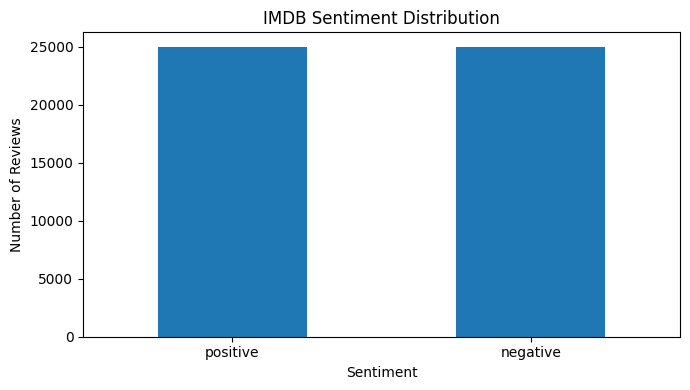

In [82]:
df["sentiment"].value_counts().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("IMDB Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [83]:
# 2-step - Matnlarni tozalash

In [84]:
import re
from html import unescape

# origanal dataset
df_clean = df.copy()

def clean_text(text):

  text = text.lower()
  # HTML belgilarini oddiy matnga aylantirish
  text = unescape(text)

  text = re.sub(r"<br\s*/?>", " ", text)
  text = re.sub(r"<[^>]+>", " ", text)

  # URL manzillarini olib tashlash
  text = re.sub(r"https?://\S+|www\.\S+", " ", text)

  # Raqamlarni olib tashlash
  text = re.sub(r"\d+", " ", text)

  # Harflardan boshqa belgilarni olib tashlash
  text = re.sub(r"[^a-z\s]", " ", text)

  # Ortiqcha bo'shliqlarni yo'qotish
  text = re.sub(r"\s+", " ", text).strip()

  return text
df_clean["review"] = df_clean["review"].apply(clean_text)


In [85]:
print("Original review:")
print(df["review"].iloc[1][:300])

print("\nCleaned review:")
print(df_clean["review"].iloc[1][:300])

Original review:
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" 

Cleaned review:
a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comforting and sometimes discomforting sense of realism to the entire piece the actors are extremely well chosen michael sheen not only has got all the polari but he has all the voices down p


In [86]:
# 3-step -  Takroriy ma'lumotlarni olib tashlash

In [87]:
print("Before removing duplicates:", len(df_clean))


Before removing duplicates: 50000


In [88]:
df_clean = df_clean.drop_duplicates(
    subset=["review", "sentiment"]
).reset_index(drop=True)

print("After removing duplicates:", len(df_clean))
print("Removed:", 50000 - len(df_clean))

After removing duplicates: 49576
Removed: 424


In [89]:
# 4-step - Sentimentni raqamga aylantirish


In [90]:
df_clean["label"] = df_clean["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(df_clean[["review", "sentiment", "label"]].head())

print("\nLabel distribution:")
print(df_clean["label"].value_counts())

                                              review sentiment  label
0  one of the other reviewers has mentioned that ...  positive      1
1  a wonderful little production the filming tech...  positive      1
2  i thought this was a wonderful way to spend ti...  positive      1
3  basically there s a family where a little boy ...  negative      0
4  petter mattei s love in the time of money is a...  positive      1

Label distribution:
label
1    24881
0    24695
Name: count, dtype: int64


In [91]:
# 5-step - Datasetni ajratish

In [92]:
from sklearn.model_selection import train_test_split
# Avval 80% train, 20% vaqtinchalik test
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.2,
    random_state = 42,
    stratify=df_clean['label']
)

In [93]:
train_df.shape

(39660, 3)

In [94]:
temp_df.shape

(9916, 3)

In [95]:
# 20% qismini validation va testga teng ajratamiz
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify = temp_df['label']
)


In [96]:
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 39660
Validation: 4958
Test: 4958


In [97]:
# 6-step - Tokenizatsiya va vocabulary

In [98]:
from collections import Counter

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

PAD_IDX = 0
UNK_IDX = 1

MAX_VOCAB_SIZE = 30000
MAX_LENGTH = 200

# Faqat train ma'lumotlaridan vocabulary yaratamiz
counter = Counter()
for review in train_df['review']:
  counter.update(review.split())

# Eng ko'p uchraydigan so'zlarni tanlash
most_common_words = counter.most_common(MAX_VOCAB_SIZE - 2)
vocab = {
    PAD_TOKEN: PAD_IDX,
    UNK_TOKEN: UNK_IDX
}

for word, _ in most_common_words:
  vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))
print("PAD index:", vocab[PAD_TOKEN])
print("UNK index:", vocab[UNK_TOKEN])

print("\nExample:")
print(list(vocab.items())[:15])

Vocabulary size: 30000
PAD index: 0
UNK index: 1

Example:
[('<PAD>', 0), ('<UNK>', 1), ('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('is', 7), ('it', 8), ('in', 9), ('i', 10), ('this', 11), ('that', 12), ('s', 13), ('was', 14)]


In [99]:
# 7-step - Matnlarni indekslarga aylantirish

In [100]:
# Encoding va padding

In [101]:
import torch
def encode_review(review, vocab, max_length=MAX_LENGTH):
  tokens = review.split()

  # So'zlarni indekslarga aylantirish
  ids = [
      vocab.get(token, UNK_IDX)
      for token in tokens
  ]

  # Uzunlikni cheklash
  ids = ids[:max_length]
# padding

  if len(ids) < max_length:
    ids += [PAD_IDX] * (max_length - len(ids))

  return ids
# Bitta sharhni tekshirish
sample_review = train_df["review"].iloc[0]

encoded = encode_review(sample_review, vocab)

print("Review:", sample_review[:200])
print("Encoded length:", len(encoded))
print("First 30 indices:", encoded[:30])

Review: in watching how the two brothers interact and feed off of each other through the whole movie makes me personally happy to live in the rural area much like they did in the movie i have watched this mov
Encoded length: 200
First 30 indices: [9, 150, 87, 2, 109, 1097, 6567, 3, 4933, 123, 5, 251, 77, 144, 2, 221, 16, 164, 69, 1226, 652, 6, 421, 9, 2, 3785, 1547, 73, 39, 33]


In [102]:
# padding mask yoki packed sequences tushunchalarni korib chiqish

In [103]:
# 8-step. PyTorch Dataset va DataLoader

In [104]:
import torch
from torch.utils.data import Dataset, DataLoader

class IMDBDataset(Dataset):
  def __init__(self, dataframe, vocab, max_length=MAX_LENGTH):
    self.review = dataframe["review"].tolist()
    self.labels = dataframe['label'].tolist()
    self.vocab = vocab
    self.max_length = max_length
  def __len__(self):
      return len(self.review)
  def __getitem__(self, index):
    review = self.review[index]
    label = self.labels[index]

    encoded = encode_review(
            review,
            self.vocab,
            self.max_length
        )

    return (
            torch.tensor(encoded, dtype=torch.long),
            torch.tensor(label, dtype=torch.float32)
        )

In [105]:
train_dataset = IMDBDataset(train_df, vocab)
val_dataset = IMDBDataset(val_df, vocab)
test_dataset = IMDBDataset(test_df, vocab)

In [106]:
print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 39660
Validation samples: 4958
Test samples: 4958


In [107]:
train_dataset

In [108]:
# DataLoader yaratish

In [109]:
BATCH_SIZE = 64
train_loader = DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size = BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size = BATCH_SIZE,
    shuffle=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 620
Validation batches: 78
Test batches: 78


In [110]:
reviews, labels = next(iter(train_loader))

print("Reviews shape:", reviews.shape)
print("Labels shape:", labels.shape)

print("\nFirst review indices:")
print(reviews[0][:30])

print("\nFirst label:")
print(labels[0])

print("\nData types:")
print(reviews.dtype)
print(labels.dtype)

Reviews shape: torch.Size([64, 200])
Labels shape: torch.Size([64])

First review indices:
tensor([  17,  107,  159,   10,  190,   10,   14,    2,   63,  392,   23,    2,
        1261,   36,   68,  108, 8914,    3,   10,  232,   37, 1215,    6,  831,
          12,   10,  232,   24,    2,   63])

First label:
tensor(1.)

Data types:
torch.int64
torch.float32


In [111]:
# 9-step - Embedding

In [112]:
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
NUM_CLASSES = 1

In [113]:
import torch
import torch.nn as nn

vocab_size = len(vocab)

embedding = nn.Embedding(
    num_embeddings=vocab_size,
    embedding_dim=EMBEDDING_DIM,
    padding_idx=PAD_IDX
)
# Bitta batch olamiz
reviews, labels = next(iter(train_loader))

# So'z indekslarini embedding vektorlariga aylantiramiz
embedded = embedding(reviews)

print("Input shape:", reviews.shape)
print("Embedding output shape:", embedded.shape)


Input shape: torch.Size([64, 200])
Embedding output shape: torch.Size([64, 200, 128])


In [114]:
# 10-bosqich - LSTM modelini qurish

In [115]:
class SentimentLSTM(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        padding_idx
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # [batch, sequence_length]
        embedded = self.embedding(x)

        # LSTM chiqishi
        _, (hidden, cell) = self.lstm(embedded)

        # Oxirgi qatlamning yakuniy hidden state'i
        last_hidden = hidden[-1]

        # Bitta logit
        output = self.fc(last_hidden)

        return output.squeeze(1)

In [116]:
class SentimentGRU(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        padding_idx
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx
        )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # So'z indekslarini embedding vektorlariga aylantirish
        embedded = self.embedding(x)

        # GRU orqali ketma-ketlikni qayta ishlash
        _, hidden = self.gru(embedded)

        # Oxirgi qatlamning yakuniy hidden state'i
        last_hidden = hidden[-1]

        # Binary classification uchun bitta logit
        output = self.fc(last_hidden)

        return output.squeeze(1)

In [117]:
lstm_model = SentimentLSTM(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    padding_idx=PAD_IDX
).to(device)

print(lstm_model)

SentimentLSTM(
  (embedding): Embedding(30000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [118]:
gru_model = SentimentGRU(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    padding_idx=PAD_IDX
).to(device)

print(gru_model)

SentimentGRU(
  (embedding): Embedding(30000, 128, padding_idx=0)
  (gru): GRU(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [119]:
total_params = sum(
    p.numel()
    for p in lstm_model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {total_params:,}")

Trainable parameters: 3,972,225


In [120]:
reviews, labels = next(iter(train_loader))
reviews = reviews.to(device)

with torch.no_grad():
    logits = lstm_model(reviews)

print("Input shape:", reviews.shape)
print("Output shape:", logits.shape)
print("First 5 logits:", logits[:5])

Input shape: torch.Size([64, 200])
Output shape: torch.Size([64])
First 5 logits: tensor([0.0741, 0.2029, 0.0741, 0.0265, 0.0741], device='cuda:0')


In [121]:
# LSTM modelini yaratish
lstm_model = SentimentLSTM(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    padding_idx=PAD_IDX
).to(device)

# Bitta batch olish
reviews, labels = next(iter(train_loader))
reviews = reviews.to(device)

# Har ikkala modelni tekshirish
with torch.no_grad():
    lstm_output = lstm_model(reviews)
    gru_output = gru_model(reviews)

print("Input shape:", reviews.shape)
print("LSTM output shape:", lstm_output.shape)
print("GRU output shape:", gru_output.shape)

Input shape: torch.Size([64, 200])
LSTM output shape: torch.Size([64])
GRU output shape: torch.Size([64])


In [122]:
def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

print(f"LSTM parameters: {count_parameters(lstm_model):,}")
print(f"GRU parameters:  {count_parameters(gru_model):,}")

LSTM parameters: 3,972,225
GRU parameters:  3,939,201


In [123]:
# training


In [124]:
import time
import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Qurilmani tekshirish
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def train_model(model, train_loader, val_loader, epochs=3):
    model = model.to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    start_time = time.time()

    for epoch in range(epochs):
        # TRAIN
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for reviews, labels in train_loader:
            reviews = reviews.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(reviews)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * labels.size(0)

            predictions = (logits >= 0).float()
            train_correct += (predictions == labels).sum().item()
            train_total += labels.size(0)
        train_loss /= train_total
        train_acc = train_correct / train_total

        # VALIDATION
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for reviews, labels in val_loader:
                reviews = reviews.to(device)
                labels = labels.to(device)

                logits = model(reviews)
                loss = criterion(logits, labels)

                val_loss += loss.item() * labels.size(0)

                predictions = (logits >= 0).float()
                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_loss /= val_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # Eng yaxshi model vaznlarini saqlash
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )
    model.load_state_dict(best_weights)

    elapsed = time.time() - start_time
    print(f"Training time: {elapsed:.2f} seconds")

    return model, history, elapsed

Device: cuda


In [125]:
lstm_model = SentimentLSTM(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    padding_idx=PAD_IDX
)

lstm_model, lstm_history, lstm_time = train_model(
    lstm_model,
    train_loader,
    val_loader,
    epochs=5
)

Epoch 1/5 | Train Loss: 0.6921 | Val Loss: 0.6956 | Train Acc: 0.5169 | Val Acc: 0.5046
Epoch 2/5 | Train Loss: 0.6345 | Val Loss: 0.4947 | Train Acc: 0.6266 | Val Acc: 0.7858
Epoch 3/5 | Train Loss: 0.3621 | Val Loss: 0.3375 | Train Acc: 0.8489 | Val Acc: 0.8522
Epoch 4/5 | Train Loss: 0.2400 | Val Loss: 0.3187 | Train Acc: 0.9073 | Val Acc: 0.8697
Epoch 5/5 | Train Loss: 0.1649 | Val Loss: 0.3451 | Train Acc: 0.9420 | Val Acc: 0.8747
Training time: 41.17 seconds


In [126]:
gru_model = SentimentGRU(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    padding_idx=PAD_IDX
)

gru_model, gru_history, gru_time = train_model(
    gru_model,
    train_loader,
    val_loader,
    epochs=5
)

Epoch 1/5 | Train Loss: 0.6941 | Val Loss: 0.6907 | Train Acc: 0.5090 | Val Acc: 0.5758
Epoch 2/5 | Train Loss: 0.5998 | Val Loss: 0.5627 | Train Acc: 0.6515 | Val Acc: 0.6668
Epoch 3/5 | Train Loss: 0.4619 | Val Loss: 0.4452 | Train Acc: 0.7586 | Val Acc: 0.7568
Epoch 4/5 | Train Loss: 0.3184 | Val Loss: 0.3435 | Train Acc: 0.8633 | Val Acc: 0.8511
Epoch 5/5 | Train Loss: 0.2199 | Val Loss: 0.3202 | Train Acc: 0.9155 | Val Acc: 0.8665
Training time: 34.31 seconds


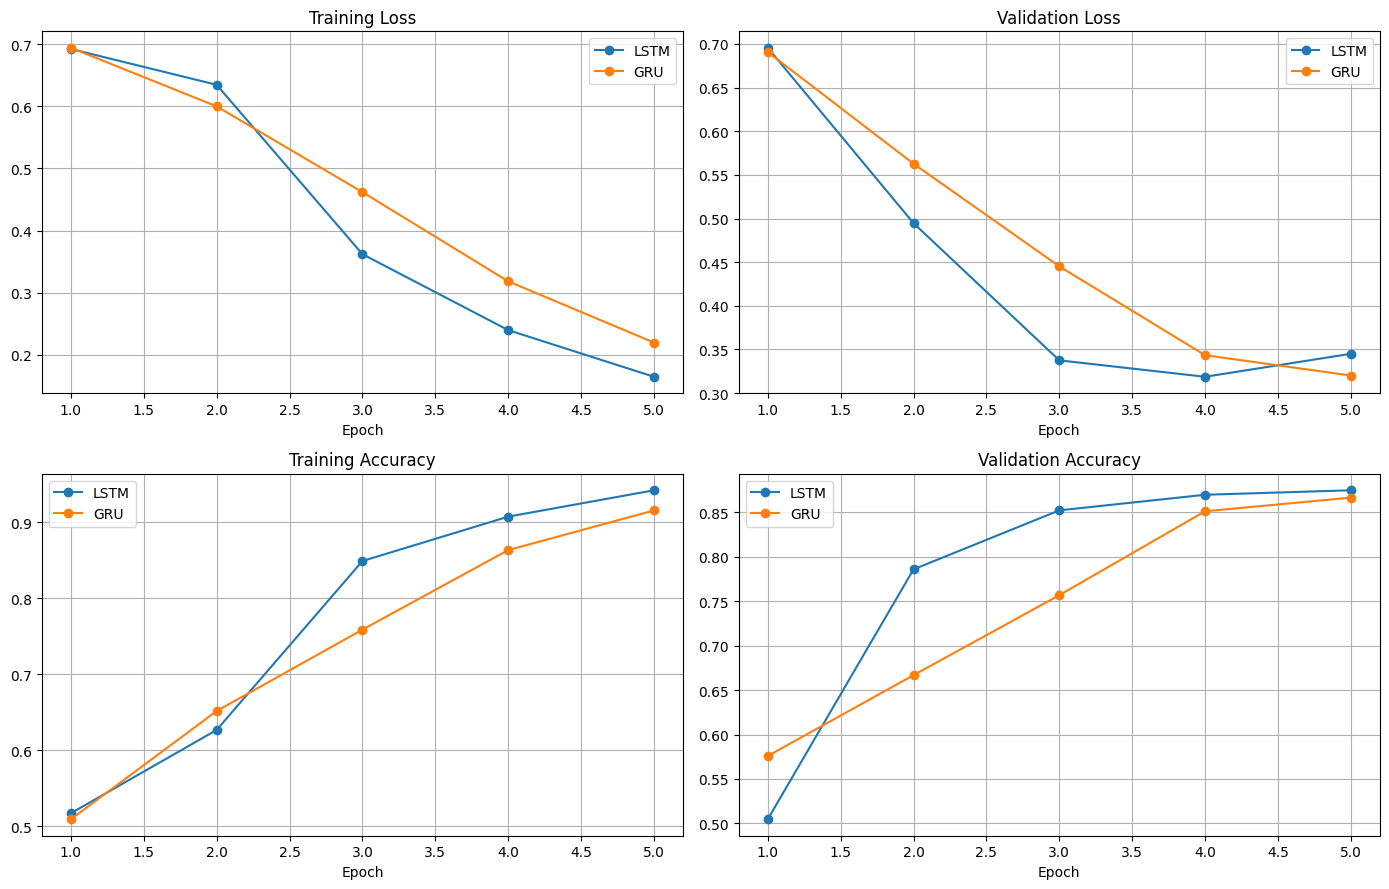

In [127]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

histories = [
    ("LSTM", lstm_history),
    ("GRU", gru_history)
]

for name, history in histories:
    epochs_range = range(1, len(history["train_loss"]) + 1)

    axes[0, 0].plot(
        epochs_range, history["train_loss"], marker="o",
        label=name
    )
    axes[0, 1].plot(
        epochs_range, history["val_loss"], marker="o",
        label=name
    )
    axes[1, 0].plot(
        epochs_range, history["train_acc"], marker="o",
        label=name
    )
    axes[1, 1].plot(
        epochs_range, history["val_acc"], marker="o",
        label=name
    )

axes[0, 0].set_title("Training Loss")
axes[0, 1].set_title("Validation Loss")
axes[1, 0].set_title("Training Accuracy")
axes[1, 1].set_title("Validation Accuracy")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [128]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import torch
import time


def evaluate_model(model, test_loader, model_name):
    model.eval()

    all_preds = []
    all_labels = []

    start_time = time.time()

    with torch.no_grad():
        for reviews, labels in test_loader:
            reviews = reviews.to(device)

            outputs = model(reviews)

            predictions = (outputs >= 0.5).long()

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    evaluation_time = time.time() - start_time

    accuracy = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)

    print(f"\n{'=' * 40}")
    print(f"{model_name} — Test Results")
    print(f"{'=' * 40}")

    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Evaluation time: {evaluation_time:.2f} seconds")

    print("\nClassification Report:")
    print(
        classification_report(
            all_labels,
            all_preds,
            target_names=["Negative", "Positive"],
            digits=4
        )
    )

    cm = confusion_matrix(all_labels, all_preds)

    return {
        "model": model_name,
        "accuracy": accuracy,
        "f1_score": f1,
        "evaluation_time": evaluation_time,
        "confusion_matrix": cm
    }


lstm_results = evaluate_model(
    lstm_model,
    test_loader,
    "LSTM"
)

gru_results = evaluate_model(
    gru_model,
    test_loader,
    "GRU"
)


LSTM — Test Results
Accuracy: 0.8637
F1-score: 0.8606
Evaluation time: 0.57 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8453    0.8891    0.8666      2470
    Positive     0.8839    0.8384    0.8606      2488

    accuracy                         0.8637      4958
   macro avg     0.8646    0.8637    0.8636      4958
weighted avg     0.8647    0.8637    0.8636      4958


GRU — Test Results
Accuracy: 0.8548
F1-score: 0.8455
Evaluation time: 0.57 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8141    0.9182    0.8630      2470
    Positive     0.9070    0.7918    0.8455      2488

    accuracy                         0.8548      4958
   macro avg     0.8605    0.8550    0.8543      4958
weighted avg     0.8607    0.8548    0.8542      4958



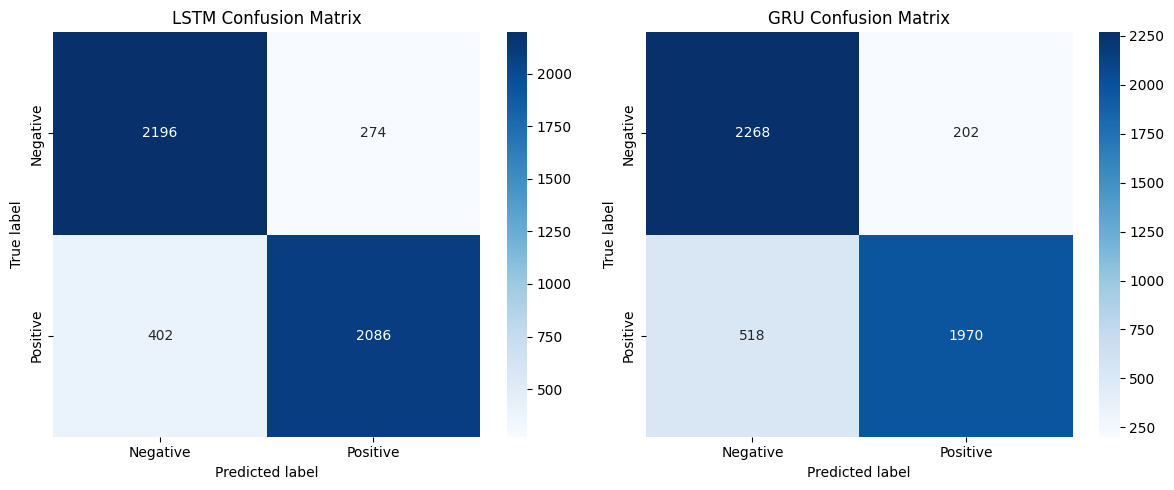

In [129]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix
import torch


def get_predictions(model, loader):
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for reviews, labels in loader:
            reviews = reviews.to(device)

            outputs = model(reviews)

            predictions = (outputs >= 0.5).long()

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_predictions


# Ikkala model uchun prediction olish
lstm_y_true, lstm_y_pred = get_predictions(
    lstm_model, test_loader
)

gru_y_true, gru_y_pred = get_predictions(
    gru_model, test_loader
)


# Confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_true, y_pred, name in [
    (axes[0], lstm_y_true, lstm_y_pred, "LSTM"),
    (axes[1], gru_y_true, gru_y_pred, "GRU")
]:
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

# Final Conclusion: LSTM vs GRU

## Project Objective

The objective of this project was to build and compare two
recurrent neural network models, LSTM and GRU, for binary
sentiment classification using the IMDb Movie Reviews dataset.

The models classify movie reviews into two categories:
- Negative
- Positive

## Experimental Results

The LSTM model achieved 86.37% test accuracy and a
positive-class F1-score of 86.06%.

The GRU model achieved 85.48% test accuracy and a
positive-class F1-score of 84.55%.

Both models were evaluated on the same test set containing
4,958 reviews.

## Model Comparison

LSTM achieved better overall classification performance.
It also showed a higher recall for positive reviews.

GRU achieved higher recall for negative reviews, meaning
it correctly identified a larger proportion of negative
reviews than LSTM.

In the current configuration, GRU had 33,024 fewer
trainable parameters than LSTM.

Both models had an evaluation time of approximately
0.57 seconds in the recorded experiment.

## Overfitting Analysis

During the 10-epoch experiment, the GRU model showed signs
of overfitting: training loss continued to decrease while
validation loss increased.

The final experiment used 5 epochs. Validation loss and
validation accuracy were monitored to understand how well
the models generalized to unseen data.

## Final Conclusion

LSTM was the stronger model in terms of overall test
accuracy and F1-score in this experiment.

GRU was better at identifying negative reviews and had
slightly fewer trainable parameters.

These results apply to the current dataset, preprocessing
pipeline, hyperparameters, and training setup. They do not
establish that LSTM is always better than GRU.

## Future Improvements

- Add early stopping based on validation loss.
- Experiment with dropout and learning-rate tuning.
- Compare training time under identical conditions.
- Save model checkpoints and preprocessing artifacts.
- Prepare a browser-compatible inference solution.
- Build a professional frontend demonstration.